# EDA MovieLens-1M

Mục đích: hiểu dữ liệu để giải thích các lựa chọn về sau (shrinkage, CSR, chia tập). Chữ trên biểu đồ bằng tiếng Anh.

## 1. Đọc dữ liệu

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data import load

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ml-1m"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

ratings = load.load_ratings(RAW_DIR)

n_rows = len(ratings)
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
missing_vals = ratings.isnull().sum()

print("=== DATASET OVERVIEW ===")
print(f"- Total ratings: {n_rows:,}")
print(f"- Total users: {n_users:,}")
print(f"- Total movies: {n_movies:,}")
print("\n=== MISSING VALUES ===")
print(missing_vals)

=== DATASET OVERVIEW ===
- Total ratings: 1,000,209
- Total users: 6,040
- Total movies: 3,706

=== MISSING VALUES ===
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


## 2. Phân phối điểm

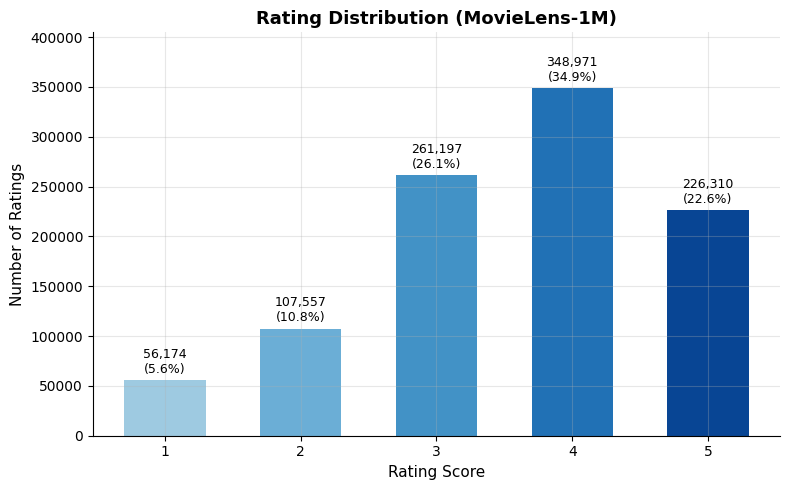

In [4]:
import matplotlib.pyplot as plt

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

fig, ax = plt.subplots(figsize=(8, 5))

rating_counts = ratings["rating"].value_counts().sort_index()
scores = [str(int(s)) for s in rating_counts.index]
counts = rating_counts.values
colors = ["#9ecae1", "#6baed6", "#4292c6", "#2171b5", "#084594"]

bars = ax.bar(scores, counts, color=colors, width=0.6)

ax.set_title("Rating Distribution (MovieLens-1M)", fontsize=13, fontweight="bold")
ax.set_xlabel("Rating Score", fontsize=11)
ax.set_ylabel("Number of Ratings", fontsize=11)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

total_ratings = len(ratings)
for bar in bars:
    height = int(bar.get_height())
    pct = (height / total_ratings) * 100
    ax.annotate(
        f"{height:,}\n({pct:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points",
    )

ax.set_ylim(0, max(counts) * 1.16)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_rating_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét phân phối điểm số

- **Thiên kiến đánh giá tích cực (Positivity Bias):** Điểm **4 sao** chiếm tỷ trọng cao nhất (**34.9%**), tiếp theo là **3 sao** (**26.1%**) và **5 sao** (**22.6%**). Tổng cộng **83.6%** lượt đánh giá nằm từ mức 3 sao trở lên, kéo điểm trung bình toàn cục lên mức $\mu \approx 3.58$.
- **Hệ quả cho mô hình:** Do phân phối điểm lệch dương rõ rệt, pipeline huấn luyện cần tách và cố định thành phần trung bình toàn cục ($\mu$) cùng độ lệch cá nhân ($b_u, b_i$) qua `BiasBaseline` trước khi phân rã ma trận phần dư.

## 3. Phân phối đuôi dài của user và phim


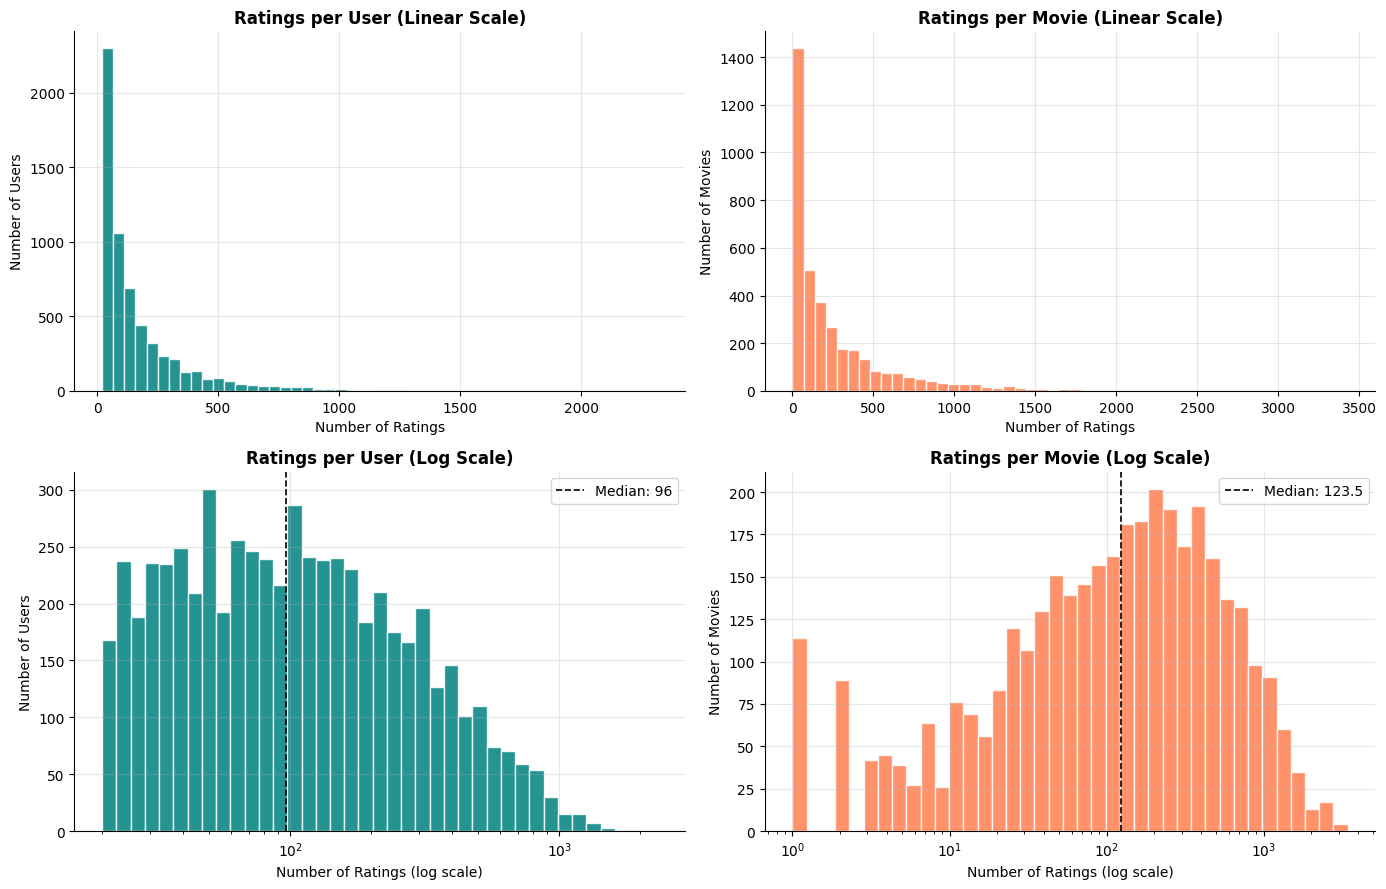

=== USER ACTIVITY QUANTILES ===
0.10     27.00
0.25     44.00
0.50     96.00
0.75    208.00
0.90    400.00
0.99    906.66
dtype: float64

=== MOVIE POPULARITY QUANTILES ===
0.10       7.0
0.25      33.0
0.50     123.5
0.75     350.0
0.90     729.5
0.99    1784.9
dtype: float64


In [5]:
import numpy as np

user_counts = ratings.groupby("user_id").size()
movie_counts = ratings.groupby("movie_id").size()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. User - Linear Scale
axes[0, 0].hist(user_counts, bins=50, color="teal", edgecolor="white", alpha=0.85)
axes[0, 0].set_title("Ratings per User (Linear Scale)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Number of Ratings")
axes[0, 0].set_ylabel("Number of Users")

# 2. Movie - Linear Scale
axes[0, 1].hist(movie_counts, bins=50, color="coral", edgecolor="white", alpha=0.85)
axes[0, 1].set_title("Ratings per Movie (Linear Scale)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Number of Ratings")
axes[0, 1].set_ylabel("Number of Movies")

# 3. User - Log Scale
user_bins = np.logspace(np.log10(user_counts.min()), np.log10(user_counts.max()), 40)
axes[1, 0].hist(user_counts, bins=user_bins, color="teal", edgecolor="white", alpha=0.85)
axes[1, 0].set_xscale("log")
axes[1, 0].axvline(user_counts.median(), color="black", linestyle="--", linewidth=1.2, label=f"Median: {user_counts.median():.0f}")
axes[1, 0].set_title("Ratings per User (Log Scale)", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Number of Ratings (log scale)")
axes[1, 0].set_ylabel("Number of Users")
axes[1, 0].legend()

# 4. Movie - Log Scale
movie_bins = np.logspace(np.log10(movie_counts.min()), np.log10(movie_counts.max()), 40)
axes[1, 1].hist(movie_counts, bins=movie_bins, color="coral", edgecolor="white", alpha=0.85)
axes[1, 1].set_xscale("log")
axes[1, 1].axvline(movie_counts.median(), color="black", linestyle="--", linewidth=1.2, label=f"Median: {movie_counts.median():.1f}")
axes[1, 1].set_title("Ratings per Movie (Log Scale)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Number of Ratings (log scale)")
axes[1, 1].set_ylabel("Number of Movies")
axes[1, 1].legend()

for ax in axes.flat:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_long_tail.png", dpi=300, bbox_inches="tight")
plt.show()

print("=== USER ACTIVITY QUANTILES ===")
print(user_counts.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))
print("\n=== MOVIE POPULARITY QUANTILES ===")
print(movie_counts.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

### Nhận xét phân phối đuôi dài và lý do cần Shrinkage, Regularization

**1. Phân phối đuôi dài (Long-tail):**

- **User:** Trung vị đạt 96 lượt đánh giá (25% ít nhất đánh giá từ 44 phim trở xuống; top 1% đánh giá hơn 906 phim).
- **Phim:** Trung vị đạt 123.5 lượt đánh giá (10% phim ít phổ biến nhất chỉ có từ 7 lượt trở xuống; top 1% có hơn 1,785 lượt).
- **Tác dụng của Log-scale:** Trên thang tuyến tính, đa số dữ liệu bị dồn sát trục tung do độ rộng cột cố định. Chuyển sang thang logarit giúp nén dải động theo cấp số nhân, đưa phân phối về dạng gần đối xứng quanh trung vị để dễ quan sát.

---

**2. Vì sao cần Shrinkage (`baseline.reg`):**

- Các phim hoặc user ở vùng đuôi dài có số lượng tương tác rất nhỏ nên trung bình thô dễ bị nhiễu (ví dụ: một bộ phim chỉ có 1 lượt đánh giá 5 sao sẽ bị xếp điểm cao hơn cả những phim kinh điển có hàng nghìn lượt 4.5 sao).
- Mô hình `BiasBaseline` cộng thêm tham số điều chuẩn `baseline.reg` ($\lambda = 10$ trong config) vào mẫu số: `b_hat = tổng(r - mu) / (số lượt đánh giá + baseline.reg)`.
- Khi số lượt đánh giá rất nhỏ so với `baseline.reg`, độ lệch tiến về 0, giúp kéo điểm ước lượng của các đối tượng ít dữ liệu về gần mức trung bình toàn cục mu (khoảng 3.58), loại bỏ sai lệch do cỡ mẫu nhỏ.

---

**3. Vì sao cần hệ số phạt Regularization ($\lambda$) khi phân rã ma trận:**

- Nhóm cố định các thành phần lệch từ `BiasBaseline` rồi mới phân rã ma trận trên phần dư `r_res = r - (mu + bu + bi)` với hàm mất mát bổ sung thành phần phạt L2: `Loss = tổng(r_res - p^T q)^2 + lambda * (||p||^2 + ||q||^2)`.
- Với các phim hoặc user ít tương tác, các vector đặc trưng ẩn ($p, q$) rất dễ bị học vẹt (overfitting) theo vài điểm số cá biệt. Hệ số phạt $\lambda$ giúp ghìm độ lớn các vector này về gần 0 khi thiếu dữ liệu cập nhật, giúp mô hình tổng quát hóa tốt hơn trên tập kiểm thử.

## 4. Độ thưa và bộ nhớ


Total possible interactions: 22,384,240
Observed interactions (full dataset): 1,000,209
Matrix sparsity (full dataset): 95.53%

=== MEMORY COMPARISON ON FULL DATASET (DENSE VS CSR) ===
1. CSR Matrix memory (float64): 11.47 MB
2. Dense Matrix memory (float64): 170.78 MB
=> CSR saves 14.9x memory compared to Dense.


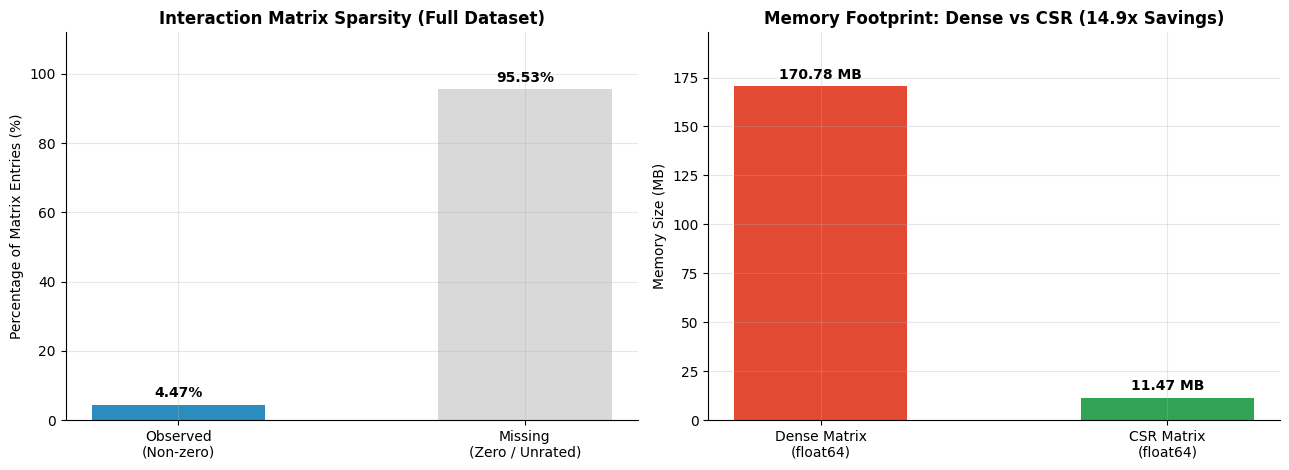

In [6]:
from src.data import sparse

shape = (n_users, n_movies)
total_possible = shape[0] * shape[1]
actual_interactions = len(ratings)
sparsity = (1.0 - (actual_interactions / total_possible)) * 100

print(f"Total possible interactions: {total_possible:,}")
print(f"Observed interactions (full dataset): {actual_interactions:,}")
print(f"Matrix sparsity (full dataset): {sparsity:.2f}%\n")

# Ánh xạ ID về chỉ số liên tục 0 -> N-1
user_codes = ratings["user_id"].astype("category").cat.codes.to_numpy()
item_codes = ratings["movie_id"].astype("category").cat.codes.to_numpy()
values = ratings["rating"].to_numpy()

csr_mat = sparse.build_csr(user_codes, item_codes, values, shape)

dense_bytes = sparse.dense_memory_bytes(shape)  # Mặc định float64
csr_bytes = sparse.csr_memory_bytes(csr_mat)

dense_mb = dense_bytes / (1024 ** 2)
csr_mb = csr_bytes / (1024 ** 2)
ratio = dense_bytes / csr_bytes

print("=== MEMORY COMPARISON ON FULL DATASET (DENSE VS CSR) ===")
print(f"1. CSR Matrix memory (float64): {csr_mb:.2f} MB")
print(f"2. Dense Matrix memory (float64): {dense_mb:.2f} MB")
print(f"=> CSR saves {ratio:.1f}x memory compared to Dense.")

# Xuất hình reports/figures/eda_sparsity.png
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

density = 100.0 - sparsity
bars1 = axes[0].bar(
    ["Observed\n(Non-zero)", "Missing\n(Zero / Unrated)"],
    [density, sparsity],
    color=["#2b8cbe", "#d9d9d9"],
    width=0.5,
)
axes[0].set_title("Interaction Matrix Sparsity (Full Dataset)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Percentage of Matrix Entries (%)")
axes[0].set_ylim(0, 112)
for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(
        f"{h:.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2.0, h),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        xytext=(0, 3),
        textcoords="offset points",
    )

bars2 = axes[1].bar(
    ["Dense Matrix\n(float64)", "CSR Matrix\n(float64)"],
    [dense_mb, csr_mb],
    color=["#e34a33", "#31a354"],
    width=0.5,
)
axes[1].set_title(f"Memory Footprint: Dense vs CSR ({ratio:.1f}x Savings)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Memory Size (MB)")
axes[1].set_ylim(0, dense_mb * 1.16)
for bar in bars2:
    h = bar.get_height()
    axes[1].annotate(
        f"{h:.2f} MB",
        xy=(bar.get_x() + bar.get_width() / 2.0, h),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        xytext=(0, 3),
        textcoords="offset points",
    )

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_sparsity.png", dpi=300, bbox_inches="tight")
plt.show()

### Nhận xét độ thưa và hiệu quả lưu trữ CSR

- **Độ thưa trên toàn bộ dữ liệu:** Ma trận tương tác kích thước 6,040 x 3,706 có tổng cộng 22,384,240 ô nhưng chỉ có 1,000,209 lượt đánh giá thực tế (**4.47%**), tương ứng độ thưa **95.53%**.
- **Hiệu quả bộ nhớ (tính trên toàn bộ 1M đánh giá):** Ma trận Dense (`float64`) tốn **170.78 MB**, trong khi định dạng nén **CSR** chỉ tốn **11.47 MB**, tiết kiệm gấp **14.9 lần** (khi lưu riêng tập train 80% ở bước tiền xử lý thì dung lượng CSR giảm còn **9.6 MB**, tiết kiệm **18.6 lần**). Ngoài tiết kiệm RAM, CSR cho phép truy xuất nhanh từng hàng user, khớp với thao tác cập nhật của thuật toán ALS.

## 5. Kết luận cho các bước sau

1. **Xử lý thiên kiến điểm số (Bias):** Dữ liệu lệch dương mạnh với 83.6% lượt đánh giá từ 3 sao trở lên (trung bình toàn cục khoảng 3.58). Mô hình cần cố định thành phần trung bình toàn cục và độ lệch cá nhân (`bu`, `bi`) thông qua `BiasBaseline` trước khi phân rã phần dư.

2. **Kiểm soát đuôi dài:** Áp dụng tham số điều chuẩn `baseline.reg` ($\lambda = 10$) cho mô hình cơ sở và tinh chỉnh hệ số phạt $\lambda$ trên tập validation cho mô hình phân rã ma trận phần dư để tránh overfitting ở nhóm user/phim ít tương tác.

3. **Lưu trữ ma trận thưa (CSR):** Tính trên toàn bộ dữ liệu, ma trận tương tác có độ thưa 95.53% và định dạng CSR (`float64`) chỉ tốn 11.47 MB, tiết kiệm gấp 14.9 lần so với Dense (170.78 MB), đồng thời tối ưu tốc độ truy xuất theo hàng cho thuật toán ALS.

4. **Chiến lược chia tập dữ liệu (Train/Val/Test) & Cold-start:** Nhóm chia ngẫu nhiên theo từng đánh giá theo tỷ lệ **80/10/10** (`seed = 42`). Do phân phối đuôi dài có tới **10% phim chỉ nhận từ 7 đánh giá trở xuống**, việc chia ngẫu nhiên làm phát sinh các trường hợp cold-start thực tế (18 dòng ở tập validation và 18 dòng ở tập test có user/phim vắng mặt ở tập train), do đó bước tiền xử lý áp dụng cơ chế chuyển các mẫu này về tập huấn luyện (`move_cold_start_to_train`).